In [1]:
import sys

sys.path.append("../src/")

In [2]:
from kmeans import CustomKmeansPlusPlus
from sklearn.feature_extraction.text import TfidfVectorizer
from datasets import load_dataset
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

dataset = load_dataset("Bitext/Bitext-customer-support-llm-chatbot-training-dataset")
corpus = dataset['train']['instruction'][ :2000 ]
corpus

['question about cancelling order {{Order Number}}',
 'i have a question about cancelling oorder {{Order Number}}',
 'i need help cancelling puchase {{Order Number}}',
 'I need to cancel purchase {{Order Number}}',
 'I cannot afford this order, cancel purchase {{Order Number}}',
 'can you help me cancel order {{Order Number}}?',
 'I can no longer afford order {{Order Number}}, cancel it',
 'I am trying to cancel purchase {{Order Number}}',
 'I have got to cancel purchase {{Order Number}}',
 'i need help canceling purchase {{Order Number}}',
 'i dont know what to do to cancel order {{Order Number}}',
 'I have a problem with cancelling purchase {{Order Number}}',
 'problem with canceling purchase {{Order Number}}',
 'can you help me canceling order {{Order Number}}?',
 'help  me canceling purchase {{Order Number}}',
 'can you help me cancel purchase {{Order Number}}?',
 'what do I have to do to cancel purchase {{Order Number}}?',
 'I bought the same item twice, cancel order {{Order Numbe

In [3]:
vectorizer = TfidfVectorizer(max_features=1500, stop_words='english')
X = vectorizer.fit_transform(corpus).toarray()
X

array([[0.        , 0.        , 0.        , ..., 0.        , 0.        ,
        0.        ],
       [0.        , 0.        , 0.        , ..., 0.        , 0.        ,
        0.        ],
       [0.        , 0.        , 0.        , ..., 0.        , 0.        ,
        0.        ],
       ...,
       [0.        , 0.        , 0.        , ..., 0.56831833, 0.        ,
        0.        ],
       [0.        , 0.        , 0.        , ..., 0.        , 0.        ,
        0.        ],
       [0.        , 0.        , 0.        , ..., 0.        , 0.        ,
        0.        ]], shape=(2000, 285))

In [4]:
model = CustomKmeansPlusPlus(k=8, max_iters=100, random_state=42)
model.fit(X)

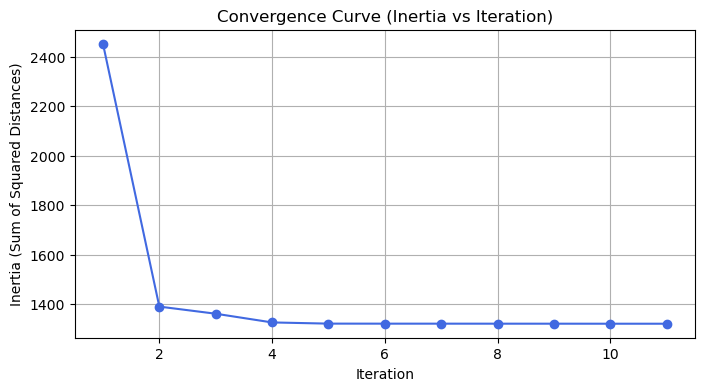

In [5]:
plt.figure(figsize=(8, 4))
plt.plot(range(1, len(model.inertia_history) + 1), model.inertia_history, marker='o', color='royalblue')
plt.title("Convergence Curve (Inertia vs Iteration)")
plt.xlabel("Iteration")
plt.ylabel("Inertia (Sum of Squared Distances)")
plt.grid(True)
plt.show()

# Finding Optimal K: Elbow method

K=2 -> Inertia: 1624.45
K=3 -> Inertia: 1535.87
K=5 -> Inertia: 1485.93
K=8 -> Inertia: 1321.58
K=12 -> Inertia: 1232.81
K=16 -> Inertia: 1180.10
K=20 -> Inertia: 1085.51


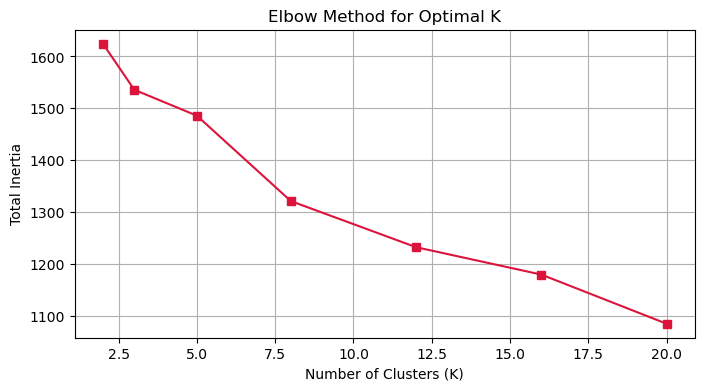

In [6]:
# for elbow method, choosing a list of K values
K_values = [2, 3, 5, 8, 12, 16, 20]
inertias = []

for k in K_values:
    model = CustomKmeansPlusPlus(k=k, max_iters=150)
    model.fit(X)
    inertias.append(model.inertia_)
    print(f"K={k} -> Inertia: {model.inertia_:.2f}")

plt.figure(figsize=(8, 4))
plt.plot(K_values, inertias, marker='s', color='crimson')
plt.title("Elbow Method for Optimal K")
plt.xlabel("Number of Clusters (K)")
plt.ylabel("Total Inertia")
plt.grid(True)
plt.show()

K=3 -> Inertia: 1535.87
K=5 -> Inertia: 1485.93
K=8 -> Inertia: 1321.58
K=12 -> Inertia: 1232.81
K=16 -> Inertia: 1180.10
K=20 -> Inertia: 1085.51


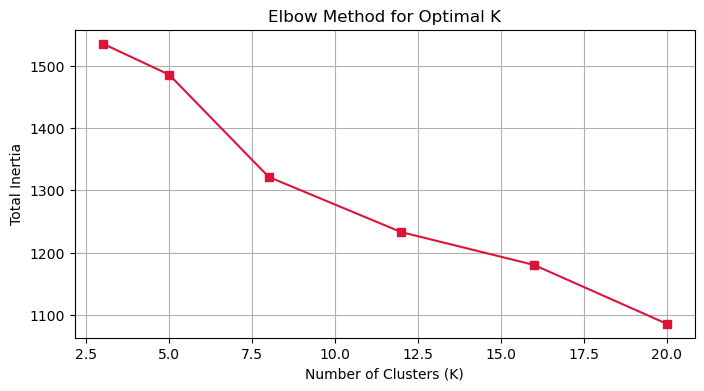

In [7]:
k_values = [3, 5, 8, 12, 16, 20]
inertias = []

for k in k_values:
    model = CustomKmeansPlusPlus(k=k, max_iters=50, random_state=42)
    model.fit(X)
    inertias.append(model.inertia_)
    print(f"K={k} -> Inertia: {model.inertia_:.2f}")

plt.figure(figsize=(8, 4))
plt.plot(k_values, inertias, marker='s', color='crimson')
plt.title("Elbow Method for Optimal K")
plt.xlabel("Number of Clusters (K)")
plt.ylabel("Total Inertia")
plt.grid(True)
plt.show()

We need to reverse-engineer our centroids back into words to understand what each cluster represents. Since a centroid is just an average of TF-IDF vectors, its highest values correspond to the most defining words for that cluster.

In [8]:
feature_names = vectorizer.get_feature_names_out()
feature_names

array(['370795561790will', 'abut', 'acn', 'add', 'adding', 'address',
       'afford', 'aford', 'amde', 'aout', 'arford', 'aritcles', 'article',
       'articles', 'artilce', 'artile', 'asistance', 'assiostance',
       'assisgance', 'assistajce', 'assistanc', 'assistancde',
       'assistance', 'assistanmce', 'assistnace', 'bloody', 'bought',
       'ca', 'cacneling', 'camcel', 'camceling', 'camt', 'cance',
       'cancel', 'cancelation', 'cancelig', 'cancelin', 'canceling',
       'cancelinv', 'cancellation', 'cancelliing', 'cancelling',
       'cancelliung', 'cancellkng', 'cancellng', 'cancellung',
       'cancelnig', 'cancelong', 'cancep', 'cancle', 'cange', 'cani',
       'canm', 'canmcel', 'canno', 'cannotdelete', 'cannotedit', 'canot',
       'canxeling', 'casncel', 'catn', 'cfanceling', 'change', 'changing',
       'chnaging', 'cncel', 'cnceling', 'colud', 'correc', 'correct',
       'correcting', 'corrrect', 'cqn', 'culd', 'cxancel', 'dad', 'damn',
       'deete', 'deeting', '

In [9]:
len(feature_names), len(model.centroids[0])

(285, 285)

In [10]:
top_n_words = 5

print("Top terms per cluster:")
for i, centroid in enumerate(model.centroids):
    # argsort n elements by default its in ascending, we need last n words as they are more frequently occuring.
    top_word_indices = np.argsort(centroid)[-top_n_words:][::-1]
    top_words = [feature_names[idx] for idx in top_word_indices]
    print(f"Cluster {i}:, {", ".join(top_words)}")

Top terms per cluster:
Cluster 0:, canceling, order, help, purchase, number
Cluster 1:, want, order, number, assistance, help
Cluster 2:, edit, order, number, purchase, help
Cluster 3:, update, order, number, purchase, want
Cluster 4:, cancelling, order, help, purchase, number
Cluster 5:, add, order, number, item, items
Cluster 6:, change, order, number, purchase, help
Cluster 7:, changing, order, number, help, purchase
Cluster 8:, cancel, purchase, number, order, help
Cluster 9:, item, order, number, swap, help
Cluster 10:, possible, cancel, order, purchase, number
Cluster 11:, helo, switch, order, number, ya
Cluster 12:, article, switch, order, number, purchase
Cluster 13:, articles, order, number, add, remove
Cluster 14:, afford, longer, order, number, pay
Cluster 15:, problems, canceling, cancelling, order, purchase
Cluster 16:, modify, order, number, purchase, mistake
Cluster 17:, cancel, order, number, know, dont
Cluster 18:, order, number, correct, purchase, swap
Cluster 19:, ed

Words are helpful, but reading the actual tickets closest to the centroid gives us the absolute ground truth of what the cluster captured.

In [11]:
sq_dists = model._compute_distances(X)
sq_dists

array([[1.25454707, 1.134714  , 1.43927232, ..., 1.1001398 , 0.94165196,
        1.54262644],
       [1.41968466, 1.29745247, 1.58682285, ..., 1.24492763, 1.05694332,
        1.65342251],
       [1.26953763, 1.19212007, 1.51642145, ..., 1.13937621, 0.97132704,
        1.57831758],
       ...,
       [1.57136532, 1.45614455, 1.68376328, ..., 1.33756935, 1.13428574,
        1.70039848],
       [1.57136532, 1.45614455, 1.68376328, ..., 1.33756935, 1.13377753,
        0.91963955],
       [1.50121304, 1.39028171, 1.65882632, ..., 1.31644135, 1.07340567,
        1.66707829]], shape=(2000, 20))

In [12]:
for i in range(model.k):
    print(f"------- Cluster {i} core tickets -------")
    # belongs to class k.
    cluster_dists = sq_dists[:, i]
    # Only consider tickets actually assigned to this cluster
    member_indices = np.where(model.labels == i)[0]
    # Sort members by their distance to the centroid
    closest_members = cluster_dists[member_indices]
    top_5_labels = member_indices[np.argsort(closest_members)[:5]]
    # print(f"Top 5 labels for cluster {k}: {top_5_labels}")
    for idx in top_5_labels:
        print(f' - {corpus[idx]}')

------- Cluster 0 core tickets -------
 - help canceling purchase {{Order Number}}
 - help canceling purchase {{Order Number}}
 - help with canceling purchase {{Order Number}}
 - could you help me canceling purchase {{Order Number}}?
 - help with canceling purchase {{Order Number}}
------- Cluster 1 core tickets -------
 - I want help to cancel purchase {{Order Number}}
 - i want help to cancel purchase {{Order Number}}
 - I want help to cancel purchase {{Order Number}}
 - want help to cancel purchase {{Order Number}}
 - i want help to cancel purchase {{Order Number}}
------- Cluster 2 core tickets -------
 - edit order {{Order Number}}
 - how to edit order {{Order Number}}
 - edit order {{Order Number}}
 - I have to edit order {{Order Number}}, how do I do it?
 - how to edit order {{Order Number}}
------- Cluster 3 core tickets -------
 - how to update order {{Order Number}}?
 - can I update order {{Order Number}}?
 - can I update order {{Order Number}}?
 - update order {{Order Number

# Finding Optimal K: Silhouette Score

s(i) = b(i) - a(i) / max(b(i), a(i))

average the silhouette score of all datapoints in a dataset across multiple K values and choose the best average. That shall be the best K value.

In [13]:
from sklearn.metrics import silhouette_score

k_values = [3, 5, 8, 12, 16, 20]

for k in k_values:
    model = CustomKmeansPlusPlus(k=k, max_iters=50, random_state=42)
    model.fit(X)
    inertias.append(model.inertia_)
    tfidf_silhouette_score = silhouette_score(X, model.labels)
    print(tfidf_silhouette_score)

0.0614601840152727
0.06604299828660384
0.12004650562719202
0.14865635000629182
0.15594836990190253
0.17652608138933915


# Comparing with sklearn

In [14]:
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score, silhouette_samples
from sklearn.preprocessing import StandardScaler
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.decomposition import PCA
import numpy as np
import matplotlib.pyplot as plt

# ── 1. TF-IDF Vectorization ────────────────────────────────────────────
tfidf = TfidfVectorizer(
    max_features=5000,     # top 5000 terms by TF-IDF score
    stop_words='english', # remove common words
    ngram_range=(1, 2),    # unigrams + bigrams
    min_df=5,              # ignore terms in fewer than 5 docs
    sublinear_tf=True      # log(1 + tf) dampens high-freq terms
)
X_tfidf = tfidf.fit_transform(corpus).toarray()

# ── 2. Fit KMeans ─────────────────────────────────────────────────────
km = KMeans(
    n_clusters=12,
    init='k-means++',  # same as your implementation
    n_init=10,          # 10 restarts, best inertia kept
    max_iter=300,
    tol=1e-4,
    random_state=42
)
km_labels = km.fit_predict(X_tfidf)

sklearn_sil_score = silhouette_score(X_tfidf, km_labels)
print(f'Custom KMeansPlusPlus score: {tfidf_silhouette_score:.4f}')
print(f'sklearn KmeansPlusPlus score: {sklearn_sil_score:.4f}')

Custom KMeansPlusPlus score: 0.1765
sklearn KmeansPlusPlus score: 0.1296


# Visualising using UMAP with 2 components

Running UMAP dimensionality reduction (this takes a few seconds)...


/opt/miniconda3/envs/myenv/lib/python3.14/site-packages/umap/umap_.py:1952: UserWarning: n_jobs value 1 overridden to 1 by setting random_state. Use no seed for parallelism.
  warn(


UMAP Projection Shape: (2000, 2)


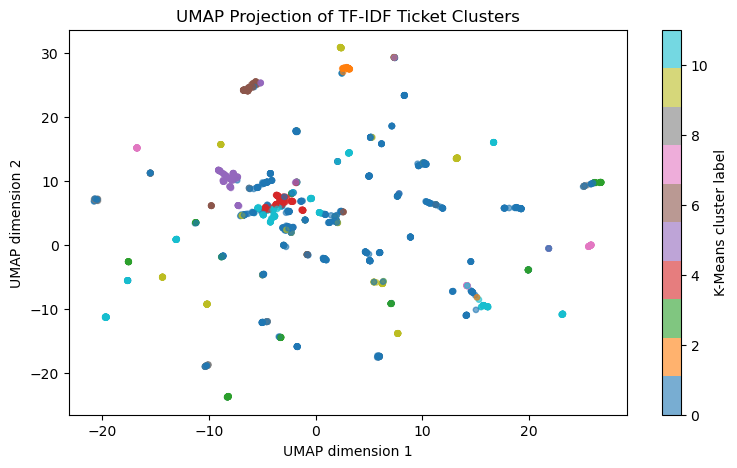

In [15]:
from matplotlib import pyplot as plt
import umap

umap_reducer = umap.UMAP(
    n_components=2,
    metric='cosine',
    min_dist=0.1,
    n_neighbors=15,
    random_state=42
)

print("Running UMAP dimensionality reduction (this takes a few seconds)...")
X_umap = umap_reducer.fit_transform(X)
print(f"UMAP Projection Shape: {X_umap.shape}")

plt.figure(figsize=(9,5))
scatter = plt.scatter(
    X_umap[:, 0],
    X_umap[:, 1],
    c=km.fit_predict(X),
    cmap='tab10',
    alpha=0.6,
    s=15
)

plt.title("UMAP Projection of TF-IDF Ticket Clusters")
plt.xlabel('UMAP dimension 1')
plt.ylabel('UMAP dimension 2')
plt.colorbar(scatter, label="K-Means cluster label")
plt.show()

# from sklearn.decomposition import PCA

# pca = PCA(n_components=2, random_state=42)
# X_pca = pca.fit_transform(X)

# plt.figure(figsize=(8, 5))
# # Scatter plot, colored by the K-Means labels
# scatter = plt.scatter(X_pca[:, 0], X_pca[:, 1], c=model.labels, cmap='tab10', alpha=0.6, s=15)

# plt.title("PCA Projection of TF-IDF Ticket Clusters")
# plt.xlabel("Principal Component 1")
# plt.ylabel("Principal Component 2")
# plt.colorbar(scatter, label="Cluster Label")
# plt.show()

# Adjusted Rand Index (ARI)

In [16]:
# before calculating ARI, we need to know the ground truth labels. 'intent' column in our dataset is exactly that.
ground_truth = dataset['train']['intent'][:2000]
ground_truth

['cancel_order',
 'cancel_order',
 'cancel_order',
 'cancel_order',
 'cancel_order',
 'cancel_order',
 'cancel_order',
 'cancel_order',
 'cancel_order',
 'cancel_order',
 'cancel_order',
 'cancel_order',
 'cancel_order',
 'cancel_order',
 'cancel_order',
 'cancel_order',
 'cancel_order',
 'cancel_order',
 'cancel_order',
 'cancel_order',
 'cancel_order',
 'cancel_order',
 'cancel_order',
 'cancel_order',
 'cancel_order',
 'cancel_order',
 'cancel_order',
 'cancel_order',
 'cancel_order',
 'cancel_order',
 'cancel_order',
 'cancel_order',
 'cancel_order',
 'cancel_order',
 'cancel_order',
 'cancel_order',
 'cancel_order',
 'cancel_order',
 'cancel_order',
 'cancel_order',
 'cancel_order',
 'cancel_order',
 'cancel_order',
 'cancel_order',
 'cancel_order',
 'cancel_order',
 'cancel_order',
 'cancel_order',
 'cancel_order',
 'cancel_order',
 'cancel_order',
 'cancel_order',
 'cancel_order',
 'cancel_order',
 'cancel_order',
 'cancel_order',
 'cancel_order',
 'cancel_order',
 'cancel_order

In [17]:
np.unique(ground_truth)

array(['cancel_order', 'change_order', 'change_shipping_address'],
      dtype='<U23')

In [18]:
from sklearn.metrics import adjusted_rand_score

ari_custom_kmeans = adjusted_rand_score(ground_truth, model.labels)
ari_sklearn_kmeans = adjusted_rand_score(ground_truth, km_labels)

ari_custom_kmeans, ari_sklearn_kmeans

(0.11420146022178707, 0.12100948896879508)